# 07 – Cartes et vérification des probabilités

**Objectif :** transformer les prédictions du test (2023-2025) en **cartes**, et vérifier si les **probabilités** annoncées par le modèle sont **fiables** (si le modèle dit 10 %, est-ce que ça brûle vraiment 1 fois sur 10 ?).

## Leçon 1 – Bien trier ≠ bien calibrer

La PR-AUC mesure si le modèle **trie** bien les lignes (les plus risquées en haut). Mais pour dire « on attend 300 feux cet été », il faut aussi que les probabilités soient **au bon niveau** : c'est la **calibration**.

Un modèle peut très bien trier et être mal calibré (toutes ses probabilités ×2, par exemple). En demand planning, c'est la différence entre « bien classer les produits du plus vendu au moins vendu » et « prévoir le bon **volume** ».

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium
import branca.colormap as cm

predictions = pd.read_parquet("../data/processed/predictions_test.parquet")
communes = pd.read_csv("../data/processed/communes_med.csv", dtype={"code": str, "dept": str})
print(predictions.shape)   # 3 505 communes × 1 096 jours

(3841480, 6)


## Étape 1 – Prévu vs réalisé, au total

La somme des probabilités = le **nombre de jours avec feu attendus** (comme une espérance). On la compare au nombre réel.

In [2]:
predictions["annee"] = predictions["jour"].dt.year
bilan = predictions.groupby("annee").agg(prevus=("proba_modele", "sum"), reels=("feu", "sum"))
bilan.loc["total"] = bilan.sum()
bilan["écart"] = bilan["prevus"] / bilan["reels"] - 1
bilan.style.format({"prevus": "{:.0f}", "reels": "{:.0f}", "écart": "{:+.0%}"})

,prevus,reels,écart
annee,,,
2023,1954,1824,+7%
2024,1328,1026,+29%
2025,1373,1287,+7%
total,4655,4137,+13%


**Lecture :** sur 2023-2025, le modèle attendait **4 655** jours-commune avec feu pour **4 137** réels : une surestimation de **12 %** seulement (contre ≈ 25 % dans le projet 13). Le sous-échantillonnage **pondéré** a bien conservé le bon niveau de probabilité. L'écart est faible en 2023 et 2025 (+7 %), plus fort en 2024 (+29 %), une année particulièrement calme (1 026 jours avec feu, le plus bas de la décennie).

## Étape 2 – Par département

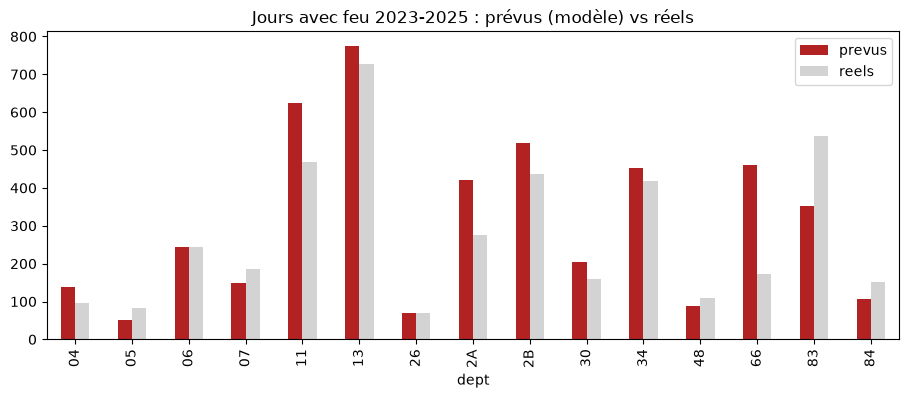

,prevus,reels,écart
dept,,,
05,53,84,-37%
83,352,537,-34%
84,107,151,-29%
48,87,109,-20%
07,150,185,-19%
06,244,243,+0%
26,69,69,+1%
13,775,728,+6%
34,452,419,+8%


In [3]:
par_dept = predictions.groupby("dept", observed=True).agg(prevus=("proba_modele", "sum"), reels=("feu", "sum"))
par_dept["écart"] = par_dept["prevus"] / par_dept["reels"] - 1

par_dept[["prevus", "reels"]].plot(kind="bar", figsize=(11, 4), color=["firebrick", "lightgrey"],
                                    title="Jours avec feu 2023-2025 : prévus (modèle) vs réels")
plt.show()
par_dept.sort_values("écart").style.format({"prevus": "{:.0f}", "reels": "{:.0f}", "écart": "{:+.0%}"})

**Lecture :** au niveau de la zone, ça tombe juste ; par département, c'est plus contrasté :
- **surestimés** : Pyrénées-Orientales (×2,7 : 459 attendus pour 173 réels), Corse-du-Sud (+53 %), Alpes-de-Haute-Provence (+42 %), Aude (+33 %) ;
- **sous-estimés** : Hautes-Alpes (−37 %), Var (−34 %), Vaucluse (−29 %).

Le modèle applique les **mêmes règles** à toute la zone. Il ne connaît d'un département que ce qui passe par ses variables (météo, historique, densité, position). Si les feux des Pyrénées-Orientales ont nettement baissé après 2022 (prévention, débroussaillement, moins d'écobuage…), le modèle ne peut pas le savoir. 👉 Piste : une **recalibration par département** sur les années récentes.

## Leçon 2 – La courbe de calibration

On range les lignes par **tranches de probabilité prédite** (0-0,1 %, 0,1-0,5 %, …), puis on compare, dans chaque tranche, la **proba moyenne annoncée** et le **taux de feu réellement observé**. Si le modèle est bien calibré, les points tombent sur la **diagonale**.

Échelle **logarithmique** (`loglog`) : les probabilités vont de 0,001 % à plus de 30 %, une échelle normale écraserait tout dans un coin.

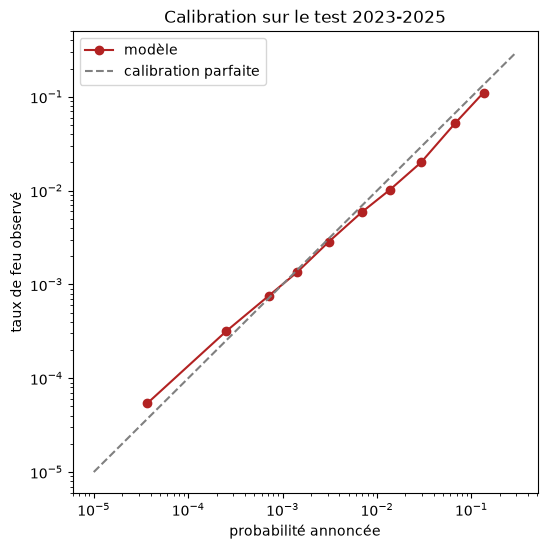

,proba_annoncee,taux_observe,lignes,feux
proba_modele,,,,
"(0.0, 0.0001]",0.004%,0.005%,1274430,69
"(0.0001, 0.0005]",0.025%,0.032%,1118961,357
"(0.0005, 0.001]",0.072%,0.076%,503422,383
"(0.001, 0.002]",0.142%,0.134%,419188,563
"(0.002, 0.005]",0.309%,0.286%,343769,982
"(0.005, 0.01]",0.687%,0.587%,111926,657
"(0.01, 0.02]",1.368%,1.020%,46456,474
"(0.02, 0.05]",2.922%,1.996%,19039,380
"(0.05, 0.1]",6.738%,5.247%,3488,183


In [4]:
bornes = [0, 0.0001, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 1]
tranche = pd.cut(predictions["proba_modele"], bins=bornes)
calib = predictions.groupby(tranche, observed=True).agg(
    proba_annoncee=("proba_modele", "mean"), taux_observe=("feu", "mean"), lignes=("feu", "size"), feux=("feu", "sum"))

fig, ax = plt.subplots(figsize=(6, 6))
ax.loglog(calib["proba_annoncee"], calib["taux_observe"], "o-", color="firebrick", label="modèle")
ax.plot([1e-5, 0.3], [1e-5, 0.3], "--", color="grey", label="calibration parfaite")
ax.set_xlabel("probabilité annoncée")
ax.set_ylabel("taux de feu observé")
ax.set_title("Calibration sur le test 2023-2025")
ax.legend()
plt.show()
calib.style.format({"proba_annoncee": "{:.3%}", "taux_observe": "{:.3%}"})

**Lecture :** les points suivent la diagonale de très près pour toutes les probabilités jusqu'à ≈ 0,5 % (l'immense majorité des lignes : 0,072 % annoncé, 0,076 % observé). Au-dessus, le modèle **surestime un peu** : quand il annonce ≈ 3 %, on observe ≈ 2 % ; quand il annonce 13 %, on observe 11 %. Les situations très risquées sont rares, donc plus difficiles à calibrer.

## Étape 3 – L'été 2023 jour par jour (toute la zone)

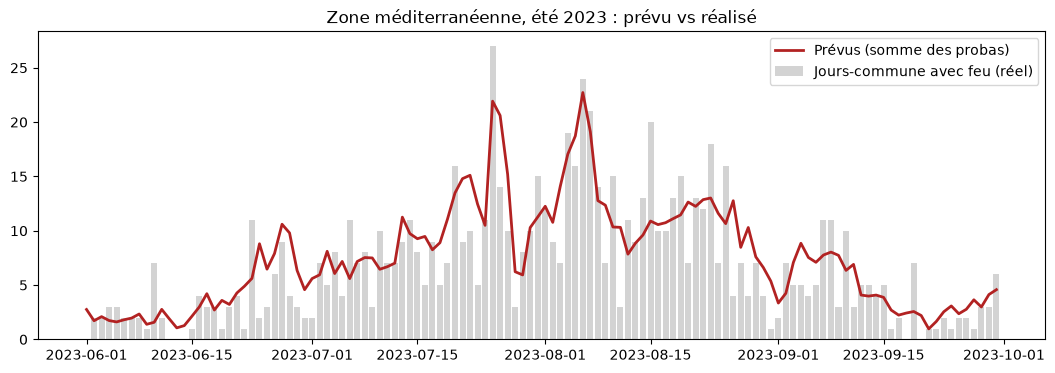

corrélation jour par jour (toute la période test) : 0.82


In [5]:
par_jour = predictions.groupby("jour").agg(prevus=("proba_modele", "sum"), reels=("feu", "sum"))
ete = par_jour.loc["2023-06-01":"2023-09-30"]

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(ete.index, ete["reels"], color="lightgrey", label="Jours-commune avec feu (réel)")
ax.plot(ete.index, ete["prevus"], color="firebrick", linewidth=2, label="Prévus (somme des probas)")
ax.set_title("Zone méditerranéenne, été 2023 : prévu vs réalisé")
ax.legend()
plt.show()
print("corrélation jour par jour (toute la période test) :", round(par_jour["prevus"].corr(par_jour["reels"]), 2))

Le modèle suit bien le **rythme** des journées dangereuses : les pics prévus tombent sur les pics réels (corrélation jour par jour **0,82** sur 2023-2025). Il ne peut pas prévoir les pics **exceptionnels** d'un jour précis (un incendiaire, une journée de mistral mal captée par le vent **moyen**…).

## Étape 4 – La carte du jour

Même fonction que dans le projet 13, avec deux adaptations à l'échelle :
- les contours viennent du fichier **simplifié** du notebook 02 (2,3 Mo pour 3 505 communes) ;
- `prefer_canvas=True` : la carte dessine les polygones sur un **canvas** (une image) au lieu de 3 505 objets SVG séparés → beaucoup plus fluide dans le navigateur.

In [6]:
contours = json.loads(Path("../data/raw/communes_med.geojson").read_text(encoding="utf-8"))
noms = dict(zip(communes["code"], communes["nom"]))
ECHELLE = ["#ffffb2", "#fecc5c", "#fd8d3c", "#e31a1c", "#800026"]

def carte_du_jour(date, vmax=0.10):
    du_jour = predictions[predictions["jour"] == date].merge(communes[["code", "nom", "lat", "lon"]], on="code")
    risque = dict(zip(du_jour["code"], du_jour["proba_modele"]))
    echelle = cm.LinearColormap(ECHELLE, vmin=0, vmax=vmax, caption=f"Probabilité de départ de feu le {date}")

    carte = folium.Map(location=[43.4, 5.5], zoom_start=7, tiles="OpenStreetMap", prefer_canvas=True)
    for f in contours["features"]:
        f["properties"]["risque"] = f"{risque.get(f['properties']['code'], 0):.1%}"
    folium.GeoJson(
        contours,
        style_function=lambda f: {"fillColor": echelle(min(risque.get(f["properties"]["code"], 0), vmax)),
                                  "color": "white", "weight": 0.3, "fillOpacity": 0.75},
        tooltip=folium.GeoJsonTooltip(fields=["nom", "risque"], aliases=["Commune", "Risque"]),
    ).add_to(carte)
    echelle.add_to(carte)

    for _, row in du_jour[du_jour["feu"] == 1].iterrows():
        folium.CircleMarker(location=[row["lat"], row["lon"]], radius=5, color="black", fill=True,
                            fill_color="black", tooltip=f"🔥 Feu réel – {row['nom']}").add_to(carte)

    print(f"{date} : {du_jour['feu'].sum()} communes avec feu, {du_jour['proba_modele'].sum():.1f} prévues")
    return carte

On choisit automatiquement le jour du test qui a eu **le plus de communes avec un feu** :

In [7]:
jour_record = par_jour["reels"].idxmax().date().isoformat()
carte_record = carte_du_jour(jour_record)
carte_record

2025-07-08 : 30 communes avec feu, 19.8 prévues


<carte folium : voir le fichier HTML dans outputs/>

In [8]:
dossier = Path("../outputs")
dossier.mkdir(exist_ok=True)
carte_record.save(dossier / f"carte_risque_{jour_record}.html")

record = predictions[predictions["jour"] == jour_record].copy()
record["rang"] = record["proba_modele"].rank(ascending=False).astype(int)
record["nom"] = record["code"].map(noms)
print(f"Rang des communes qui ont brûlé ce jour-là (sur 3 505) :")
record[record["feu"] == 1].sort_values("rang")[["nom", "dept", "proba_modele", "rang"]]

Rang des communes qui ont brûlé ce jour-là (sur 3 505) :


,nom,dept,proba_modele,rang
1476135,Martigues,13,0.268267,1
1466271,Istres,13,0.210771,4
1492575,Les Pennes-Mirabeau,13,0.202311,6
1415855,Aix-en-Provence,13,0.188331,8
2032903,Porto-Vecchio,2A,0.130455,15
1475039,Marseille,13,0.109239,19
1458599,Fuveau,13,0.102717,21
1944127,Ajaccio,2A,0.075164,29
1450927,Ensuès-la-Redonne,13,0.065206,35
1469559,Lambesc,13,0.056053,45


**Comment lire ce tableau ?** Le rang 1 est la commune jugée la plus risquée ce jour-là, sur 3 505.

Le jour record du test est le **8 juillet 2025** : **30 communes** ont eu un feu, le modèle en attendait ≈ 20 (il sous-estime l'ampleur, mais voit bien que c'est une journée exceptionnelle). Et surtout, il savait **où** : **Martigues était n°1** du classement, Istres n°4, Les Pennes-Mirabeau n°6, Aix-en-Provence n°8 ; **11 des 30 communes** touchées étaient dans le top 100 (3 % des communes), 17 dans le top 350 (10 %). Quelques feux restent imprévisibles (une commune au rang 3 214 !) : un feu, c'est aussi une étincelle humaine au hasard.

Et un jour d'hiver, pour contraste :

In [9]:
carte_hiver = carte_du_jour("2024-01-15")
carte_hiver

2024-01-15 : 1 communes avec feu, 1.9 prévues


<carte folium : voir le fichier HTML dans outputs/>

## Étape 5 – L'atlas du risque estival

Pour chaque commune, le **risque moyen d'un jour de juillet-août** sur 2023-2025, et le nombre réel de jours avec feu sur ces étés.

In [10]:
ete_test = predictions[predictions["jour"].dt.month.isin([7, 8])]
risque_ete = ete_test.groupby("code")["proba_modele"].mean()
feux_ete = ete_test.groupby("code")["feu"].sum()
vmax_ete = float(risque_ete.quantile(0.99))

echelle_ete = cm.LinearColormap(ECHELLE, vmin=0, vmax=vmax_ete,
                                caption="Risque moyen d'un jour de juillet-août (2023-2025)")
for f in contours["features"]:
    c = f["properties"]["code"]
    f["properties"]["risque_ete"] = f"{risque_ete.get(c, 0):.2%}"
    f["properties"]["feux_ete"] = int(feux_ete.get(c, 0))

atlas = folium.Map(location=[43.4, 5.5], zoom_start=7, tiles="OpenStreetMap", prefer_canvas=True)
folium.GeoJson(
    contours,
    style_function=lambda f: {"fillColor": echelle_ete(min(risque_ete.get(f["properties"]["code"], 0), vmax_ete)),
                              "color": "white", "weight": 0.3, "fillOpacity": 0.75},
    tooltip=folium.GeoJsonTooltip(fields=["nom", "risque_ete", "feux_ete"],
                                  aliases=["Commune", "Risque moyen", "Jours avec feu (étés 23-25)"]),
).add_to(atlas)
echelle_ete.add_to(atlas)
atlas.save(dossier / "atlas_risque_ete.html")

print("corrélation de rang risque / feux réels :", round(risque_ete.corr(feux_ete, method="spearman"), 2))
atlas

corrélation de rang risque / feux réels : 0.46


<carte folium : voir le fichier HTML dans outputs/>

**Corrélation de rang (Spearman)** : on compare l'**ordre** des communes (de la plus risquée à la moins risquée) selon le modèle et selon les feux réels. 1 = même ordre, 0 = aucun rapport.

Ici ≈ **0,46**, plus bas que dans le projet 13 (0,78). Ce n'est pas que le modèle est moins bon : **75 % des communes** n'ont eu **aucun** feu en juillet-août 2023-2025. Toutes ces communes sont ex aequo côté réalité, ce qui « écrase » la corrélation. Un indicateur plus parlant : les **10 % de communes** jugées les plus risquées ont concentré **49 % des jours de feu estivaux**.

👉 Les cartes sont enregistrées dans `outputs/` : ouvre-les dans ton navigateur.

## 🎯 À toi de jouer

1. Fais la carte du **14 août 2023** avec `carte_du_jour("2023-08-14")`.
2. Quel département est le plus **surestimé** par le modèle sur 2023-2025 ? Le plus sous-estimé ? (tableau de l'étape 2)

In [11]:
# à toi

<details><summary>Correction</summary>

```python
carte_du_jour("2023-08-14")
par_dept.sort_values("écart")   # en haut : sous-estimés ; en bas : surestimés
```
</details>

## Récap

1. **Trier** (PR-AUC) et **calibrer** (bon niveau de probabilité) sont deux qualités différentes.
2. Courbe de calibration : le modèle est-il fiable quand il annonce 1 %, 5 %, 20 % ?
3. Des cartes du jour lisibles à l'échelle de 3 505 communes (contours simplifiés + canvas).
4. L'atlas estival : le modèle range les communes presque dans le même ordre que les feux réels.

**Prochaine étape (08) :** les scénarios 2027 et le tableau de bord.